In [2]:
#Step 1: Import Libraries and Load the Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# Load the Iris dataset
iris_data = load_iris(as_frame=True)

# Create a DataFrame
df = iris_data.frame.copy()

# Convert numerical target labels to species names
df["species"] = df["target"].map(
    dict(enumerate(iris_data.target_names))
)

# Remove the numerical target column
df = df.drop(columns=["target"])

print(df.head())
print("\nDataset shape:", df.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Dataset shape: (150, 5)


In [3]:
#Explanation: The dataset contains 150 flower observations and five variables. Four variables are numerical measurements, while species identifies the flower species.

In [4]:
#Step 2: Identify Numerical and Categorical Variables
# Identify numerical variables
numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical variables
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical variables:")
print(numerical_columns)

print("\nCategorical variables:")
print(categorical_columns)

Numerical variables:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Categorical variables:
['species']


In [5]:
#Interpretation: Numerical variables can be summarised using measures such as mean and standard deviation. Categorical variables are commonly summarised using frequencies, proportions, and the mode.

In [7]:
#Step 3: Calculate Measures of Central Tendency
#We will examine the variable sepal length (cm)
sepal_length = df["sepal length (cm)"]

mean_value = sepal_length.mean()
median_value = sepal_length.median()
mode_value = sepal_length.mode()
print("Mean:", round(mean_value, 2))
print("Median:", round(median_value, 2))
print("Mode:", mode_value.tolist())


Mean: 5.84
Median: 5.8
Mode: [5.0]


In [9]:
#Mean: The arithmetic average of all sepal lengths.
#Median: The middle value when observations are arranged in ascending order.
#Mode: The most frequently occurring value.
#Interpretation: The mean and median are close, indicating that the centre of the sepal-length distribution is around 5.8 cm. However, these statistics alone are insufficient to determine the complete shape of the distribution.

In [11]:
#Step 4: Calculate Measures of Dispersion
minimum = sepal_length.min()
maximum = sepal_length.max()

data_range = maximum - minimum
variance = sepal_length.var()
std_dev = sepal_length.std()

Q1 = sepal_length.quantile(0.25)
Q3 = sepal_length.quantile(0.75)
IQR = Q3 - Q1

print("Minimum:", minimum)
print("Maximum:", maximum)
print("Range:", round(data_range, 2))
print("Variance:", round(variance, 2))
print("Standard deviation:", round(std_dev, 2))
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", round(IQR, 2))

Minimum: 4.3
Maximum: 7.9
Range: 3.6
Variance: 0.69
Standard deviation: 0.83
Q1: 5.1
Q3: 6.4
IQR: 1.3


In [13]:
#Range: Maximum minus minimum.
#Variance: Measures average squared deviations from the mean, using the sample variance by default in Pandas.
#Standard deviation: Measures dispersion in the original measurement units.
#Interquartile range (IQR): The difference between the third and first quartiles, describing the spread of the middle 50% of observations.
#Interpretation: Sepal lengths range from 4.3 cm to 7.9 cm. The standard deviation of approximately 0.83 cm indicates variation around the mean.

In [14]:
#Step 5: Examine Distribution Shape Using Skewness
skewness = sepal_length.skew()

print("Skewness:", round(skewness, 3))

Skewness: 0.315


In [15]:
#Interpretation: The positive skewness indicates a slight right-skewed tendency in the sepal-length distribution.
#A skewness value near zero suggests limited asymmetry, although it does not guarantee that the distribution is normal.

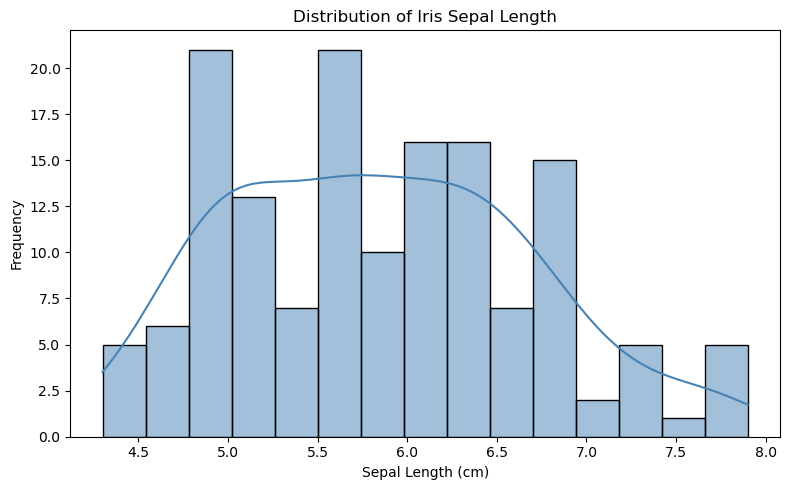

In [16]:
#Step 6: Visualise the Distribution Using a Histogram
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="sepal length (cm)",
    bins=15,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Iris Sepal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [17]:
#Explanation: A histogram divides a numerical variable into intervals called bins and shows the number of observations in each interval. The KDE curve provides a smoothed estimate of the distribution's shape.
#Interpretation: Most sepal lengths fall within the central portion of the observed range. The histogram helps reveal the concentration and spread of measurements, as well as any visible asymmetry.

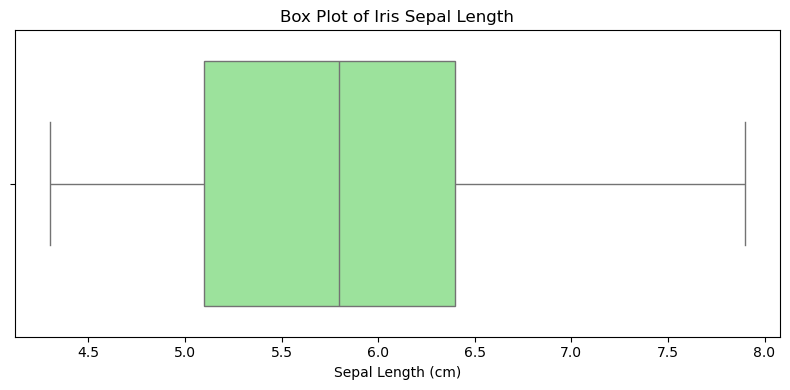

In [18]:
# Step 7: Visualise the Distribution Using a Box Plot
plt.figure(figsize=(8, 4))

sns.boxplot(
    data=df,
    x="sepal length (cm)",
    color="lightgreen"
)

plt.title("Box Plot of Iris Sepal Length")
plt.xlabel("Sepal Length (cm)")

plt.tight_layout()
plt.show()

In [19]:
#Explanation: A box plot displays the median, first quartile, third quartile, whiskers, and any potential outliers identified by the plotting convention.
#The central box represents the interquartile range. The line inside the box represents the median.
#Interpretation: The box plot provides a compact view of the distribution's centre and variability. Any points beyond the whiskers should be investigated rather than automatically treated as errors.

In [20]:
#Step 8: Perform Univariate Analysis on a Categorical Variable
# Frequency counts
species_counts = df["species"].value_counts()

print("Species frequencies:")
print(species_counts)

# Percentages
species_percentages = (
    df["species"].value_counts(normalize=True) * 100
)

print("\nSpecies percentages:")
print(species_percentages.round(2))

Species frequencies:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Species percentages:
species
setosa        33.33
versicolor    33.33
virginica     33.33
Name: proportion, dtype: float64


In [21]:
#Interpretation: The dataset contains equal numbers of observations from the three Iris species. This balance is a property of the dataset and should not be interpreted as evidence that the species occur equally frequently in nature.

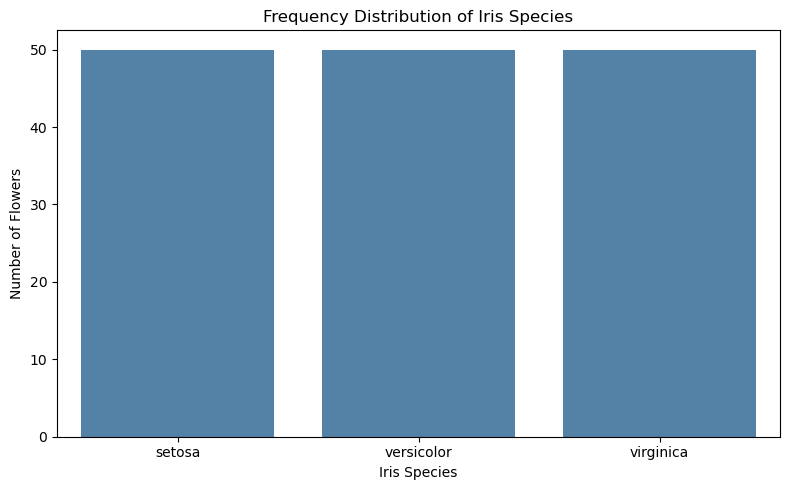

In [22]:
#Step 9: Create a Categorical Frequency Chart
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="species",
    color="steelblue"
)

plt.title("Frequency Distribution of Iris Species")
plt.xlabel("Iris Species")
plt.ylabel("Number of Flowers")

plt.tight_layout()
plt.show()

In [23]:
#Explanation: A count plot is appropriate for categorical variables because it displays the frequency of observations in each category.

In [ ]:
#Step 10: Generate a Complete Univariate Summary
